# Streams and gzip round trips

Check that compression followed by decompression recovers the exact original bytes.

Compressed length depends on the compressor and options. A byte comparison evaluates the stronger property needed here, preservation of the entire input. Input through standard input avoids embedding a source filename.

In [1]:
from pathlib import Path
import shutil, subprocess, tempfile
import matplotlib.pyplot as plt
import numpy as np

here = Path.cwd()

## Native source

`example.sh`

```sh
#!/bin/sh
set -eu
export LC_ALL=C
awk 'BEGIN {for (i=0;i<50;i++) print "sample,18"}' > readings
gzip -c < readings > readings.gz
gzip -dc < readings.gz > restored
cmp readings restored
wc -c < readings
wc -c < restored
```

## Run the shell script

The Python driver gives each installed shell its own empty working directory. Each run must agree with the independently specified fixture.

In [2]:
expected = [500, 500]
shells = [name for name in ("sh", "bash", "zsh") if shutil.which(name)]
runs = {}
for shell in shells:
    with tempfile.TemporaryDirectory() as directory:
        result = subprocess.run(
            [shell, str(here / "example.sh")],
            cwd=directory,
            check=True,
            capture_output=True,
            text=True,
        )
    numbers = [int(v) for v in result.stdout.split()]
    runs[shell] = numbers
    print(shell, numbers)
    assert numbers == expected
observed = runs[shells[0]]

sh [500, 500]
bash [500, 500]
zsh [500, 500]


## Inspect the outcome

Equal byte counts alone do not prove equality. cmp performs the full byte comparison.

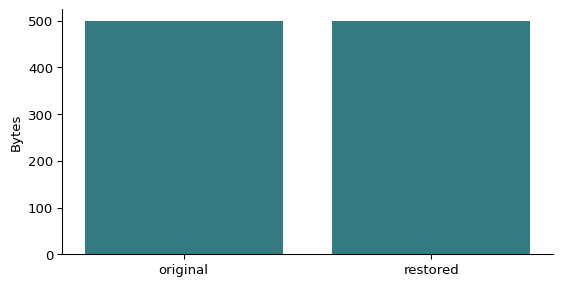

In [3]:
fig, ax = plt.subplots(figsize=(5.8, 2.9), constrained_layout=True)
ax.bar(["original", "restored"], observed, color="#357a80")
ax.set(ylabel="Bytes")
plt.show()

## Interpreting the result

Equal byte counts alone do not prove equality. cmp performs the full byte comparison.

## Exercise

Alter one byte after restoration, keep the length unchanged and observe the comparison exit status.

## References

[The Open Group, POSIX shell command language](https://pubs.opengroup.org/onlinepubs/9799919799/utilities/V3_chap02.html)

[GNU Bash reference manual](https://www.gnu.org/software/bash/manual/bash.html)

[Apple Terminal User Guide](https://support.apple.com/guide/terminal/welcome-trml2df0220c/mac)